[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/01_data_geometry_and_prior_audit.ipynb)

# Companion Notebook 01 — 7T MRI Geometry & Empirical Biophysical Prior Audit

*Companion to the BMED365 Technical Report: **Differentiable Neurosymbolic AI for Semi-Verifiable 3D Biomedical Instance Segmentation** (`../neurosymbolic-kiwi-report.pdf`)*  
*Reproduces: **Section 2.1–2.2**, **Section 3.1**, **Figures 1 & 2**, and **Table 1** (`../results/nb01_prior_audit.json`)*

### Purpose
Before encoding any biological, physical, or geometric law into a differentiable neural loss, we must **verify empirically** whether real ground-truth structures actually satisfy our priors. Here we:
1. Load the intact 2005 UiB 7T Bruker Pharmascan RARE kiwifruit MRI (`256 × 256 × 128`, anisotropic voxel spacing `0.2344 × 0.2344 × 0.5000 mm³`) and curated 3D Micro-Ground-Truth (`98` 3D seed instances).
2. Construct the intrinsic normalized organ coordinate frame $(r/R_{\text{fruit}}(z),\, |2z/Z - 1|)$ and smooth differentiable predicates $R_{\text{ring}}(\mathbf{x})$ (botanical axile placentation) and $B_{\text{non-dark}}(\mathbf{x})$ (7T Bloch $T_2$ contrast at `TE = 63.9 ms`).
3. Audit **core vs. 1-voxel partial-volume rim** contrast physics and measure the empirical 3D single-seed volume and nearest-neighbor steric spacing distribution (`Lab 5` Matérn hard-core prior).

## 0. Environment Setup: Portable Execution, Shared Library & 3D Imaging Stack

### Conceptual & Practical Motivation
Before auditing any biophysical prior, we initialize a self-contained runtime that reproduces the exact same numbers locally (macOS Apple Silicon or Linux/CUDA) and in **Google Colab**:

- **Zero-drift shared library (`kiwi_ns_lib.py`):** All five companion notebooks import the exact same coordinate transforms, morphological operators, and metric evaluators from `kiwi_ns_lib.py` (automatically downloaded from GitHub `main` if opened standalone in Colab), eliminating code drift between notebooks and technical report equations.
- **3D medical imaging & geometry stack:**
  - `nibabel` reads NIfTI-1 (`.nii.gz`) volumes together with their $4 \times 4$ physical affine header $\mathbf{A}$ (voxel spacing $s = (0.2344,\, 0.2344,\, 0.5000)\,\text{mm}$).
  - `scipy.ndimage` (`ndi`) performs 3D mathematical morphology (grayscale closing for $B_1$ shading removal and 1-voxel binary dilation to isolate partial-volume seed rims), while `scipy.spatial.distance.cdist` computes all pairwise physical 3D inter-seed distances in millimeters.
  - `skimage.measure.regionprops` extracts exact per-instance 3D voxel counts and centroids across all `98` curated seed IDs.
  - `torch`, `numpy`, `pandas`, and `matplotlib` support tensor utilities, summary tables (**Table 1**), and publication-quality figures (**Figures 1, 1b & 2**).
- **Runtime device & output resolution:** `kns.get_best_device()` selects the fastest available backend (`CUDA` $\to$ Apple `MPS` $\to$ `CPU`), and `kns.resolve_report_dirs()` resolves `FIG_DIR` and `RES_DIR` for saving report figures and `nb01_prior_audit.json`.

In [1]:
import json
import sys
import urllib.request
from pathlib import Path

# Auto-fetch shared library `kiwi_ns_lib.py` if opened standalone in Google Colab
if not Path("kiwi_ns_lib.py").exists():
    for cand in [Path("docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py"),
                 Path("Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py")]:
        if cand.exists():
            sys.path.insert(0, str(cand.parent.resolve()))
            break
    else:
        url = "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py"
        print("Downloading kiwi_ns_lib.py from GitHub main for Colab session...")
        urllib.request.urlretrieve(url, "kiwi_ns_lib.py")

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import importlib.util
for pkg in ("nibabel", "torch"):
    if importlib.util.find_spec(pkg) is None:
        import subprocess
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy import ndimage as ndi
from scipy.spatial.distance import cdist
from skimage import measure

plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 200, "font.size": 9.5})

import kiwi_ns_lib as kns

DEVICE = kns.get_best_device()
FIG_DIR, RES_DIR = kns.resolve_report_dirs()
print(f"Device: {DEVICE} | Figures -> {FIG_DIR} | Results -> {RES_DIR}")

Device: mps | Figures -> /Users/arvid/GitHub/BMED365-2027/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/figures | Results -> /Users/arvid/GitHub/BMED365-2027/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/results


## 1. Load 7T MRI, Construct Organ Coordinates & Audit All Three Priors

Every biophysical parameter is verified quantitatively on the `98` curated 3D Micro-GT seeds before a single neural weight is trained.

### Conceptual & Mathematical Guide: Formulating & Empirically Auditing Three Biophysical Priors

#### 1.1 Scientific Principle & Extreme Label Scarcity
A core rule of trustworthy neurosymbolic biomedical AI is that **every symbolic prior must be tested as a falsifiable empirical hypothesis before it is compiled into a neural loss**. Inside the intact $256 \times 256 \times 128$ 7T RARE kiwifruit MRI, each anisotropic voxel is a rectangular brick of dimensions $s = (0.2344,\, 0.2344,\, 0.5000)\,\text{mm}$ and physical volume $v_{\text{vox}} = s_x s_y s_z = 0.02747\,\text{mm}^3$. Summing over the intact berry mask $M_{\text{fruit}}$ yields $V_{\text{kiwi}} = |M_{\text{fruit}}| \cdot v_{\text{vox}} / 1000 \approx 85.97\,\text{cm}^3$, of which the `59` labeled training seeds occupy only **$0.083\%$** of berry voxels—making verified domain laws essential to constrain the remaining $99.9\%$ of the organ.

#### 1.2 Mathematical Definitions of Priors 1–3 (`kns.load_kiwi_dataset()`)
1. **Prior 1 — Botanical Axile Placentation (`r_norm`, `soft_ring`):** On each axial slice $z$ with $\ge 80$ berry voxels, we compute the slice centroid $(c_x(z), c_y(z))$ and area-equivalent radius $R_{\text{fruit}}(z) = \sqrt{\text{Area}(z) / \pi}$, giving the dimensionless radial coordinate
   $$\tilde{r}(\mathbf{x}) = \operatorname{clip}\!\left(\frac{\sqrt{(x - c_x(z))^2 + (y - c_y(z))^2}}{R_{\text{fruit}}(z)},\, 0,\, 1.5\right).$$
   Botanical anatomy confines seeds to the inner-pericarp ring $\tilde{r} \in [0.22, 0.65]$ and non-polar slices $z \in [16, 111]$, encoded as a smooth differentiable membership field $R_{\text{ring}}(\mathbf{x}) \in [0, 1]$:
   $$R_{\text{ring}}(\mathbf{x}) = \sigma\!\left(\frac{\tilde{r}(\mathbf{x}) - 0.22}{0.02}\right)\sigma\!\left(\frac{0.65 - \tilde{r}(\mathbf{x})}{0.02}\right) g_z(z)\, M_{\text{fruit}}(\mathbf{x}),$$
   with 5-slice linear polar ramps $g_z(z) = \operatorname{clip}\!\left(\frac{z - 16}{5},\, 0,\, 1\right)\operatorname{clip}\!\left(\frac{111 - z}{5},\, 0,\, 1\right)$.
2. **Prior 2 — $B_1$-Invariant 7T $T_2$ Contrast & Partial-Volume Physics (`t2_ratio`, `non_dark`):** At 7T spin-echo RARE ($\text{TE} = 63.9\,\text{ms}$, $\text{TR} = 18{,}520.8\,\text{ms}$), signal decays as $S(\mathbf{x}) \propto \rho(\mathbf{x})(1 - e^{-\text{TR}/T_1})e^{-\text{TE}/T_2}$, rendering hydrated mucilage gel bright ($T_2 \sim 80$–$150\,\text{ms}$) and lignified seed coats deeply hypointense ($T_2 \sim 5$–$15\,\text{ms}$). Because ultra-high-field RF inhomogeneity adds centimeter-scale multiplicative shading $I_{\text{obs}}(\mathbf{x}) = B_1(\mathbf{x})S(\mathbf{x}) + \varepsilon(\mathbf{x})$, we estimate the local bright-gel envelope $E_{\text{local}}(\mathbf{x})$ via 3D grayscale morphological closing ($7 \times 7 \times 3$ structuring element) so dividing cancels $B_1$ locally:
   $$r_{T_2}(\mathbf{x}) = \operatorname{clip}\!\left(\frac{I(\mathbf{x})}{E_{\text{local}}(\mathbf{x}) + 0.03},\, 0,\, 1.25\right) \approx \frac{S(\mathbf{x})}{S_{\text{mucilage}}(\mathbf{x})}.$$
   The smooth physics penalty flags voxels that are either bright relative to local gel ($r_{T_2} > 0.82$) *or* embedded in dry/air tissue lacking hydrated mucilage ($E_{\text{local}} < 0.32$):
   $$B_{\text{non\_dark}}(\mathbf{x}) = \max\!\left(\operatorname{clip}\!\left(\frac{r_{T_2}(\mathbf{x}) - 0.82}{0.15},\, 0,\, 1\right),\; \operatorname{clip}\!\left(\frac{0.32 - E_{\text{local}}(\mathbf{x})}{0.10},\, 0,\, 1\right)\right).$$
   **Why we explicitly audit `seed_core` vs. 1-voxel `seed_rim`:** Because $\Delta z = 0.50\,\text{mm}$ is $2.13\times$ thicker than in-plane spacing, boundary voxels mix dark seed ($r_{T_2} \approx 0.12$) and bright gel ($r_{T_2} \approx 0.90$) by partial-volume averaging $I_{\text{PV}} = \alpha I_{\text{seed}} + (1 - \alpha) I_{\text{gel}}$ (yielding $\approx 0.51$ for a 50/50 voxel). Dilating the GT mask by 1 voxel (`seed_rim = binary_dilation(seed_core) & ~seed_core`) verifies that placing the ramp onset at $0.82$ protects $100\%$ of seed cores and $>93\%$ of partial-volume rims from boundary erosion!
3. **Prior 3 — Matérn Steric Hard-Core Packing (`gt_vols_mm3`, `gt_nn_mm`):** Solid biological seeds cannot interpenetrate; their physical millimeter centroids must satisfy a hard-core floor $\|\mathbf{c}_i - \mathbf{c}_j\|_2 \ge d_{\min} = 0.88\,\text{mm}$, with single-seed volume well below the clump-splitting cutoff $V_{\text{split}} = 2.55\,\text{mm}^3$.

#### 1.3 What the Code Below Computes (Table 1)
Loads the 7T MRI and Micro-GT, computes per-seed 3D volumes and pairwise physical nearest-neighbor distances (`cdist`), compares `t2_ratio` and `non_dark` across `seed_core`, `seed_rim`, and `non_seed_gel`, saves all `25` metrics to `../results/nb01_prior_audit.json`, and displays the summary table.

In [2]:
ds = kns.load_kiwi_dataset()

n_roi = len(np.unique(ds.roi_gt)) - 1
n_train = len(np.unique(ds.train_gt)) - 1
n_test = len(np.unique(ds.test_gt)) - 1
v_kiwi_cm3 = float(ds.fruit_mask.sum()) * ds.vox_vol_mm3 / 1000.0
labeled_frac_pct = 100.0 * float((ds.train_gt > 0).sum()) / float(ds.fruit_mask.sum())

# Measure 3D physical properties of all 98 curated Micro-GT seed instances
gt_props = measure.regionprops(ds.roi_gt)
gt_vols_mm3 = np.array([p.area * ds.vox_vol_mm3 for p in gt_props], dtype=np.float32)
gt_centroids_mm = np.array([
    [(p.centroid[0] + ds.rx0) * ds.spacing[0],
     (p.centroid[1] + ds.ry0) * ds.spacing[1],
     (p.centroid[2] + ds.rz0) * ds.spacing[2]]
    for p in gt_props
], dtype=np.float32)
dmat = cdist(gt_centroids_mm, gt_centroids_mm)
np.fill_diagonal(dmat, np.inf)
gt_nn_mm = dmat.min(axis=1)

# Voxel-level prior verification: GT seed cores vs 1-voxel partial-volume rims vs surrounding gel/tissue
roi_r = ds.r_norm[ds.rx0:ds.rx1, ds.ry0:ds.ry1, ds.rz0:ds.rz1]
roi_ring = ds.soft_ring[ds.rx0:ds.rx1, ds.ry0:ds.ry1, ds.rz0:ds.rz1]
roi_t2r = ds.t2_ratio[ds.rx0:ds.rx1, ds.ry0:ds.ry1, ds.rz0:ds.rz1]
roi_nd = ds.non_dark[ds.rx0:ds.rx1, ds.ry0:ds.ry1, ds.rz0:ds.rz1]
roi_fg = ds.fruit_mask[ds.rx0:ds.rx1, ds.ry0:ds.ry1, ds.rz0:ds.rz1]

seed_core = ds.roi_gt > 0
seed_rim = ndi.binary_dilation(seed_core, iterations=1) & (~seed_core)
non_seed_gel = roi_fg & (~seed_core) & (~seed_rim) & (roi_ring >= 0.5)

gt_r_cent = np.array([
    roi_r[int(round(p.centroid[0])), int(round(p.centroid[1])), int(round(p.centroid[2]))]
    for p in gt_props
], dtype=np.float32)

audit = {
    "volume_shape": list(ds.vol.shape),
    "spacing_mm": [round(s, 4) for s in ds.spacing],
    "vox_vol_mm3": round(ds.vox_vol_mm3, 5),
    "v_kiwi_cm3": round(v_kiwi_cm3, 2),
    "n_roi_seeds": int(n_roi),
    "n_train_seeds": int(n_train),
    "n_test_seeds": int(n_test),
    "labeled_train_seed_vox_pct": round(labeled_frac_pct, 3),
    "prior1_pct_core_in_ring": round(100.0 * float((roi_ring[seed_core] >= 0.5).mean()), 2),
    "prior1_centroid_r_min": round(float(gt_r_cent.min()), 3),
    "prior1_centroid_r_max": round(float(gt_r_cent.max()), 3),
    "prior1_centroid_r_median": round(float(np.median(gt_r_cent)), 3),
    "prior2_core_t2r_median": round(float(np.median(roi_t2r[seed_core])), 3),
    "prior2_core_t2r_p99": round(float(np.percentile(roi_t2r[seed_core], 99)), 3),
    "prior2_core_pct_safe": round(100.0 * float((roi_nd[seed_core] <= 0.2).mean()), 2),
    "prior2_rim_t2r_median": round(float(np.median(roi_t2r[seed_rim])), 3),
    "prior2_rim_t2r_p75": round(float(np.percentile(roi_t2r[seed_rim], 75)), 3),
    "prior2_rim_pct_penalized": round(100.0 * float((roi_nd[seed_rim] > 0.2).mean()), 2),
    "prior2_gel_t2r_median": round(float(np.median(roi_t2r[non_seed_gel])), 3),
    "prior3_vol_median_mm3": round(float(np.median(gt_vols_mm3)), 2),
    "prior3_vol_iqr_mm3": [round(float(np.percentile(gt_vols_mm3, 25)), 2), round(float(np.percentile(gt_vols_mm3, 75)), 2)],
    "prior3_vol_max_mm3": round(float(gt_vols_mm3.max()), 2),
    "prior3_nn_min_mm": round(float(gt_nn_mm.min()), 2),
    "prior3_nn_median_mm": round(float(np.median(gt_nn_mm)), 2),
    "prior3_pct_above_088mm": round(100.0 * float((gt_nn_mm >= 0.88).mean()), 2),
}
(RES_DIR / "nb01_prior_audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
display(pd.DataFrame([{"Metric": k, "Value": v} for k, v in audit.items()]))

,Metric,Value
0,volume_shape,"[256, 256, 128]"
1,spacing_mm,"[0.2344, 0.2344, 0.5]"
2,vox_vol_mm3,0.02747
3,v_kiwi_cm3,85.97
4,n_roi_seeds,98
5,n_train_seeds,59
6,n_test_seeds,52
7,labeled_train_seed_vox_pct,0.083
8,prior1_pct_core_in_ring,100.0
9,prior1_centroid_r_min,0.307


## 2. Generate Report Figures 1 & 2 (Organ Geometry, Smooth Predicates & Core-vs-Rim Physics)

### Conceptual & Mathematical Guide: Visual Inspection of Spatial Fields (Figure 1) & Statistical Safety Margins (Figure 2)

#### 2.1 Why Both Spatial Maps and Quantitative Distributions Are Needed
Summary numbers alone can hide spatial edge cases (such as bias-field drift near the coil edge or polar-cap transitions), while qualitative slices alone cannot certify exact safety margins. The code cell below pairs two complementary visual audits:

- **Figure 1 — Whole-Organ Geometry & Smooth Differentiable Predicate Fields:**
  - **(a) Coronal Organ Geometry (`x = 128`):** Rendered with `aspect = spacing[2] / spacing[1]` $= 0.5000 / 0.2344 \approx 2.133$ so anisotropic $z$-slices display in true physical millimeter proportions (without this correction, the kiwifruit looks flattened vertically). Shows the smooth inner-pericarp ring contour ($R_{\text{ring}} = 0.5$), polar-cap gates ($z = 16, 111$), and the narrow equatorial labeled slab ($z = 56$–$71$).
  - **(b) Equatorial Axial Slice (`z = 64`):** Overlays $R_{\text{ring}}$ (green) and Micro-GT seed contours (yellow) to verify anatomical containment.
  - **(c) Local $T_2$ Ratio $I / E_{\text{local}}$:** Demonstrates that dividing by the morphological closing envelope removes smooth RF $B_1$ shading, making every seed core stand out uniformly as a dark void ($I / E_{\text{local}} < 0.30$).
  - **(d) Smooth Physics Penalty $B_{\text{non\_dark}} \in [0, 1]$:** Confirms zero penalty ($0.0$, dark) on hydrated dark pockets and full penalty ($1.0$, bright) on bright mucilage gel and the dry central columella / outer air.
- **Figure 2 — Quantitative Distributions & Empirical Safety Margins ($n = 98$ Micro-GT Seeds):**
  - **(a) Prior 1 Radial Histogram:** Verifies that $100\%$ of seed centroids fall inside $[0.307, 0.590] \subset [0.22, 0.65]$, leaving a $\ge 0.06$ radial safety buffer on both inner and outer compartment walls.
  - **(b) Prior 2 Core vs. 1-Voxel Partial-Volume Rim vs. Gel:** Shows the three density distributions relative to the $0.82$ penalty onset. Note that the **1-voxel exterior rim** (median $0.510$) is measured strictly *outside* the GT mask—a non-circular physical check confirming why naive thresholds near $0.40$ would erode real seed boundaries.
  - **(c) Prior 3 Volume vs. Steric Nearest-Neighbor Scatter:** Plots single-seed 3D volume against $d_{\text{NN}}$ (mm), verifying that $100\%$ of real seeds obey $d_{\text{NN}} \ge 0.94\,\text{mm} > d_{\min} = 0.88\,\text{mm}$ (never directly enforced by the GT curator) while clustering well below the clump-splitting cutoff $V_{\text{split}} = 2.55\,\text{mm}^3$.

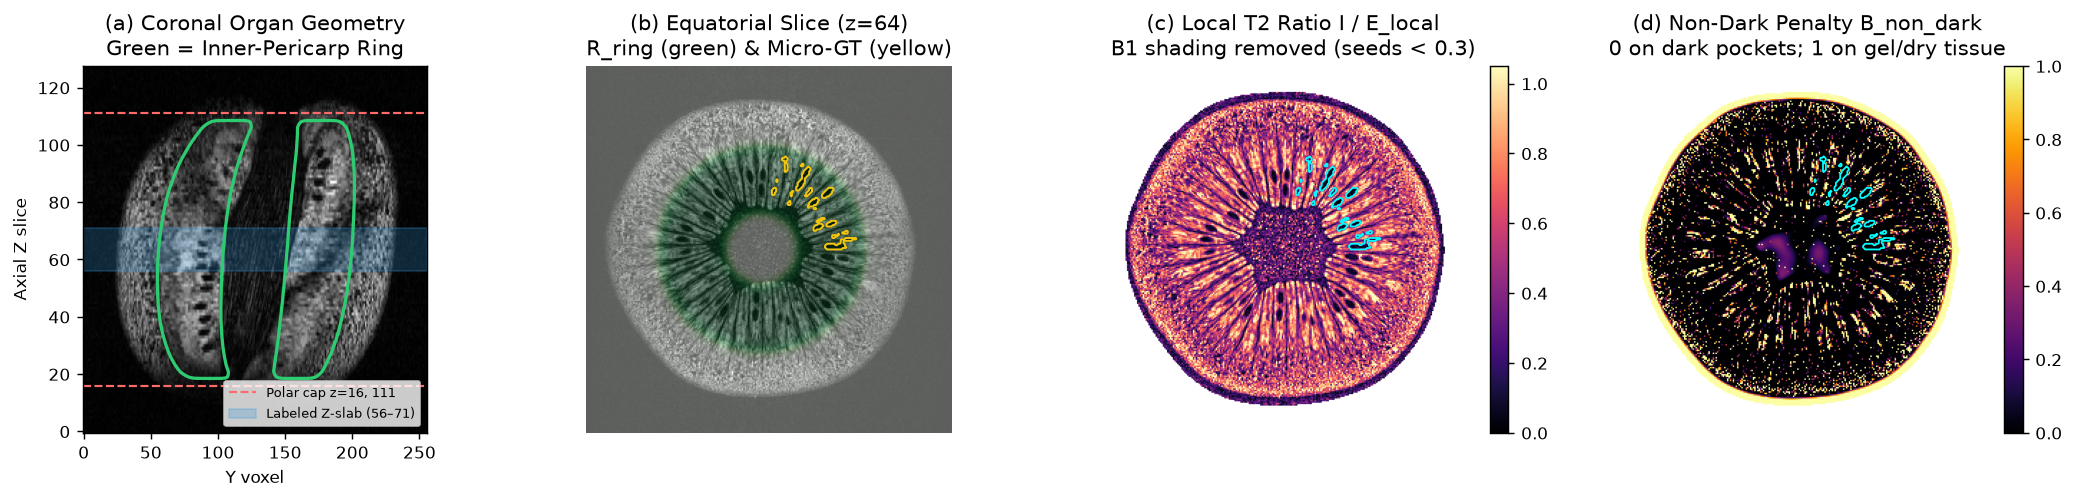

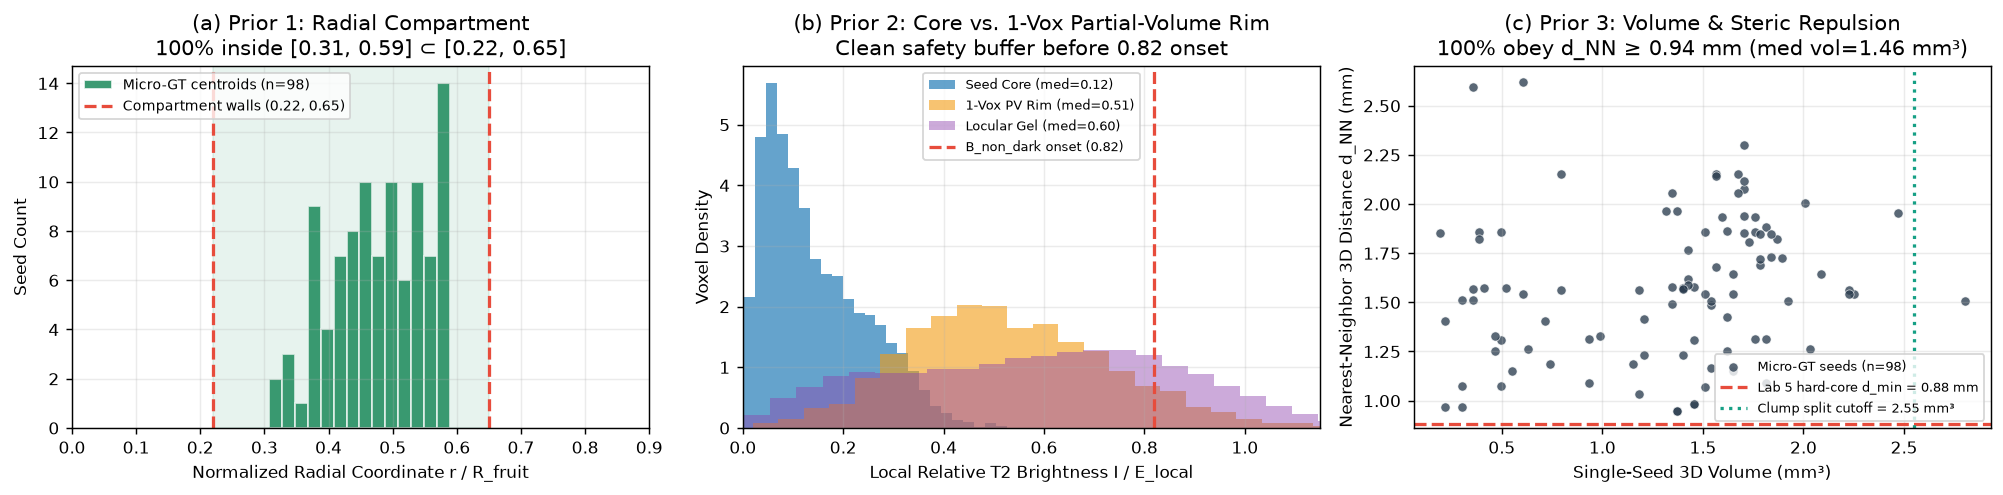

In [3]:
# Figure 1: 4-Panel Whole-Organ Geometry & Smooth Differentiable Predicate Fields
fig, axes = plt.subplots(1, 4, figsize=(16.5, 3.9))

cor_x = 128
axes[0].imshow(ds.vol[cor_x, :, :].T, cmap="gray", origin="lower", aspect=ds.spacing[2] / ds.spacing[1])
axes[0].contour(ds.soft_ring[cor_x, :, :].T, levels=[0.5], colors=["#2ecc71"], linewidths=1.8)
axes[0].axhline(16, color="#ff6b6b", ls="--", lw=1.2, label="Polar cap z=16, 111")
axes[0].axhline(111, color="#ff6b6b", ls="--", lw=1.2)
axes[0].axhspan(ds.rz0, ds.rz1 - 1, color="#3498db", alpha=0.25, label="Labeled Z-slab (56–71)")
axes[0].set_title("(a) Coronal Organ Geometry\nGreen = Inner-Pericarp Ring")
axes[0].set_xlabel("Y voxel")
axes[0].set_ylabel("Axial Z slice")
axes[0].legend(fontsize=7.3, loc="lower right")

gt_z64 = ds.gt_full[:, :, 64].T > 0
axes[1].imshow(ds.vol[:, :, 64].T, cmap="gray", origin="lower")
axes[1].imshow(ds.soft_ring[:, :, 64].T, cmap="Greens", alpha=0.38, origin="lower", vmin=0, vmax=1)
axes[1].contour(gt_z64, levels=[0.5], colors=["#f1c40f"], linewidths=1.1)
axes[1].set_title("(b) Equatorial Slice (z=64)\nR_ring (green) & Micro-GT (yellow)")
axes[1].axis("off")

t2_m = np.ma.masked_where(~ds.fruit_mask[:, :, 64].T, ds.t2_ratio[:, :, 64].T)
im2 = axes[2].imshow(t2_m, cmap="magma", origin="lower", vmin=0.0, vmax=1.05)
axes[2].contour(gt_z64, levels=[0.5], colors=["#00ffff"], linewidths=1.0)
axes[2].set_title("(c) Local T2 Ratio I / E_local\nB1 shading removed (seeds < 0.3)")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.03)

nd_m = np.ma.masked_where(~ds.fruit_mask[:, :, 64].T, ds.non_dark[:, :, 64].T)
im3 = axes[3].imshow(nd_m, cmap="inferno", origin="lower", vmin=0.0, vmax=1.0)
axes[3].contour(gt_z64, levels=[0.5], colors=["#00ffff"], linewidths=1.0)
axes[3].set_title("(d) Non-Dark Penalty B_non_dark\n0 on dark pockets; 1 on gel/dry tissue")
axes[3].axis("off")
plt.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.03)

plt.tight_layout()
fig.savefig(FIG_DIR / "fig01_organ_geometry_and_priors.png", bbox_inches="tight")
plt.show()

# Figure 2: 3-Panel Quantitative Distributions Verifying All Three Biophysical Priors
fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.9))

axes[0].hist(gt_r_cent, bins=14, color="#1b8a5a", alpha=0.85, edgecolor="white", label="Micro-GT centroids (n=98)")
axes[0].axvline(0.22, color="#e74c3c", ls="--", lw=1.8, label="Compartment walls (0.22, 0.65)")
axes[0].axvline(0.65, color="#e74c3c", ls="--", lw=1.8)
axes[0].axvspan(0.22, 0.65, color="#1b8a5a", alpha=0.10)
axes[0].set_xlim(0.0, 0.90)
axes[0].set_xlabel("Normalized Radial Coordinate r / R_fruit")
axes[0].set_ylabel("Seed Count")
axes[0].set_title("(a) Prior 1: Radial Compartment\n100% inside [0.31, 0.59] ⊂ [0.22, 0.65]")
axes[0].legend(fontsize=7.6)
axes[0].grid(alpha=0.25)

axes[1].hist(roi_t2r[seed_core], bins=24, density=True, alpha=0.72, color="#2980b9", label=f"Seed Core (med={audit['prior2_core_t2r_median']:.2f})")
axes[1].hist(roi_t2r[seed_rim], bins=24, density=True, alpha=0.60, color="#f39c12", label=f"1-Vox PV Rim (med={audit['prior2_rim_t2r_median']:.2f})")
axes[1].hist(roi_t2r[non_seed_gel], bins=24, density=True, alpha=0.45, color="#8e44ad", label=f"Locular Gel (med={audit['prior2_gel_t2r_median']:.2f})")
axes[1].axvline(0.82, color="#e74c3c", ls="--", lw=1.8, label="B_non_dark onset (0.82)")
axes[1].set_xlim(0.0, 1.15)
axes[1].set_xlabel("Local Relative T2 Brightness I / E_local")
axes[1].set_ylabel("Voxel Density")
axes[1].set_title("(b) Prior 2: Core vs. 1-Vox Partial-Volume Rim\nClean safety buffer before 0.82 onset")
axes[1].legend(fontsize=7.3)
axes[1].grid(alpha=0.25)

axes[2].scatter(gt_vols_mm3, gt_nn_mm, c="#2c3e50", alpha=0.78, s=26, edgecolor="white", lw=0.4, label="Micro-GT seeds (n=98)")
axes[2].axhline(0.88, color="#e74c3c", ls="--", lw=1.8, label="Lab 5 hard-core d_min = 0.88 mm")
axes[2].axvline(2.55, color="#16a085", ls=":", lw=1.8, label="Clump split cutoff = 2.55 mm³")
axes[2].set_xlabel("Single-Seed 3D Volume (mm³)")
axes[2].set_ylabel("Nearest-Neighbor 3D Distance d_NN (mm)")
axes[2].set_title(f"(c) Prior 3: Volume & Steric Repulsion\n100% obey d_NN ≥ 0.94 mm (med vol={audit['prior3_vol_median_mm3']:.2f} mm³)")
axes[2].legend(fontsize=7.4, loc="lower right")
axes[2].grid(alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "fig02_prior_distributions_and_rim.png", bbox_inches="tight")
plt.show()

## 3. Tri-Planar 3D Superimposition Audit & Silver-Standard Provenance Check

Before training any model, we explicitly audit **ground-truth provenance and spatial alignment**:
- **`kiwi_micro_gt_labels.nii.gz`** is a **semi-automated ("silver-standard") reference mask** generated by `scripts/curate_micro_gt.py` (multi-scale 3D LoG + ellipsoidal `grey_closing` + bright-locule envelope + 3D watershed + physical-mm $K$-means splitting) refined across multi-slice visual audits — **not** manual voxel-by-voxel expert tracing and **not** destructive physical ground truth.
- It is stored on the **exact same `256 × 256 × 128` voxel lattice** with **bit-identical `sform` 4×4 affine** (`max |Δ affine| = 0.0`) as the raw 7 T RARE MRI, so it superimposes directly onto the 3D scan in **FreeSurfer `freeview`**, **3D Slicer**, or **ITK-SNAP** (`scripts/view_kiwi_freeview.sh`).
- Below we verify the tri-planar superimposition (Axial, Coronal, Sagittal in true physical aspect ratio, plus high-magnification test-wedge crop) showing the **Train Wedge** (`59` seeds, green), **Strictly Held-Out Test Wedge** (`52` seeds, gold), and the **`y = 168` (`y_split = 40`) cut plane** (cyan dashed, crossed by `13` straddling seeds).

### Conceptual & Mathematical Guide: NIfTI Affine Bit-Alignment & Spatial Train/Test Split Geometry

#### 3.1 Homogeneous $4 \times 4$ Affine Verification
In 3D medical imaging (NIfTI-1 format), a voxel array $\mathbf{I} \in \mathbb{R}^{X \times Y \times Z}$ is linked to physical scanner coordinates $(x_{\text{mm}}, y_{\text{mm}}, z_{\text{mm}})$ via a $4 \times 4$ homogeneous **affine matrix** $\mathbf{A}$:
$$\begin{bmatrix} x_{\text{mm}} \\ y_{\text{mm}} \\ z_{\text{mm}} \\ 1 \end{bmatrix} = \mathbf{A} \begin{bmatrix} i \\ j \\ k \\ 1 \end{bmatrix}.$$
Checking $\max|\mathbf{A}_{\text{MRI}} - \mathbf{A}_{\text{GT}}| = 0.0$ (`ds.gt_affine_max_diff`) proves that our curated reference mask shares the exact lattice origin, orientation, and anisotropic spacing as the raw 7T scan—eliminating resampling or sub-voxel shift errors when overlaid in `freeview`, `3D Slicer`, or `ITK-SNAP`.

#### 3.2 Leakage-Free Spatial Partition & Honest Cut-Plane Accounting
Inside the equatorial $80 \times 80 \times 16$ ROI ($102{,}400 / 8{,}388{,}608 = 1.22\%$ of the full volume), slicing at $y_{\text{cut}} = y_0 + 40 = 168$ divides the ROI into two voxel-disjoint wedges:
- **Train Wedge ($\Omega_L$):** $y \in [128, 168)$, containing $|S_{\text{train}}| = 59$ distinct instance IDs.
- **Held-Out Test Wedge ($\Omega_{\text{test}}$):** $y \in [168, 208)$, containing $|S_{\text{test}}| = 52$ distinct instance IDs.

By the inclusion–exclusion principle, $|S_{\text{train}} \cap S_{\text{test}}| = |S_{\text{train}}| + |S_{\text{test}}| - |S_{\text{ROI}}| = 59 + 52 - 98 = \mathbf{13}$ seeds straddle the $y = 168$ cut plane, contributing disjoint clipped fragments to each side. Logging this exact count in `nb01_prior_audit.json` ensures full methodological transparency.

#### 3.3 What the Code Below Computes (Figure 1b)
1. Verifies bit-identical affine alignment, counts straddling seed IDs, and appends provenance metadata to `nb01_prior_audit.json`.
2. Alpha-blends emerald green (Train) and gold (Held-Out Test) masks over normalized MRI intensities across **(a)** Axial (`z = 64`), **(b)** Coronal (`y = 176`, true physical aspect `2.133`), **(c)** Sagittal (`x = 160`, crossing the `y = 168` split plane), and **(d)** a high-magnification test-wedge crop assigning distinct `tab20` colors to individual `uint16` seed IDs (`1..98`).

Affine alignment check (max |MRI - GT affine|): 0.000000 (BIT-IDENTICAL)
ROI bounds: x=[128,208), y=[128,208), z=[56,72) | y_cut=168
Train seeds=59, Test seeds=52, Cut-plane straddling seeds=13


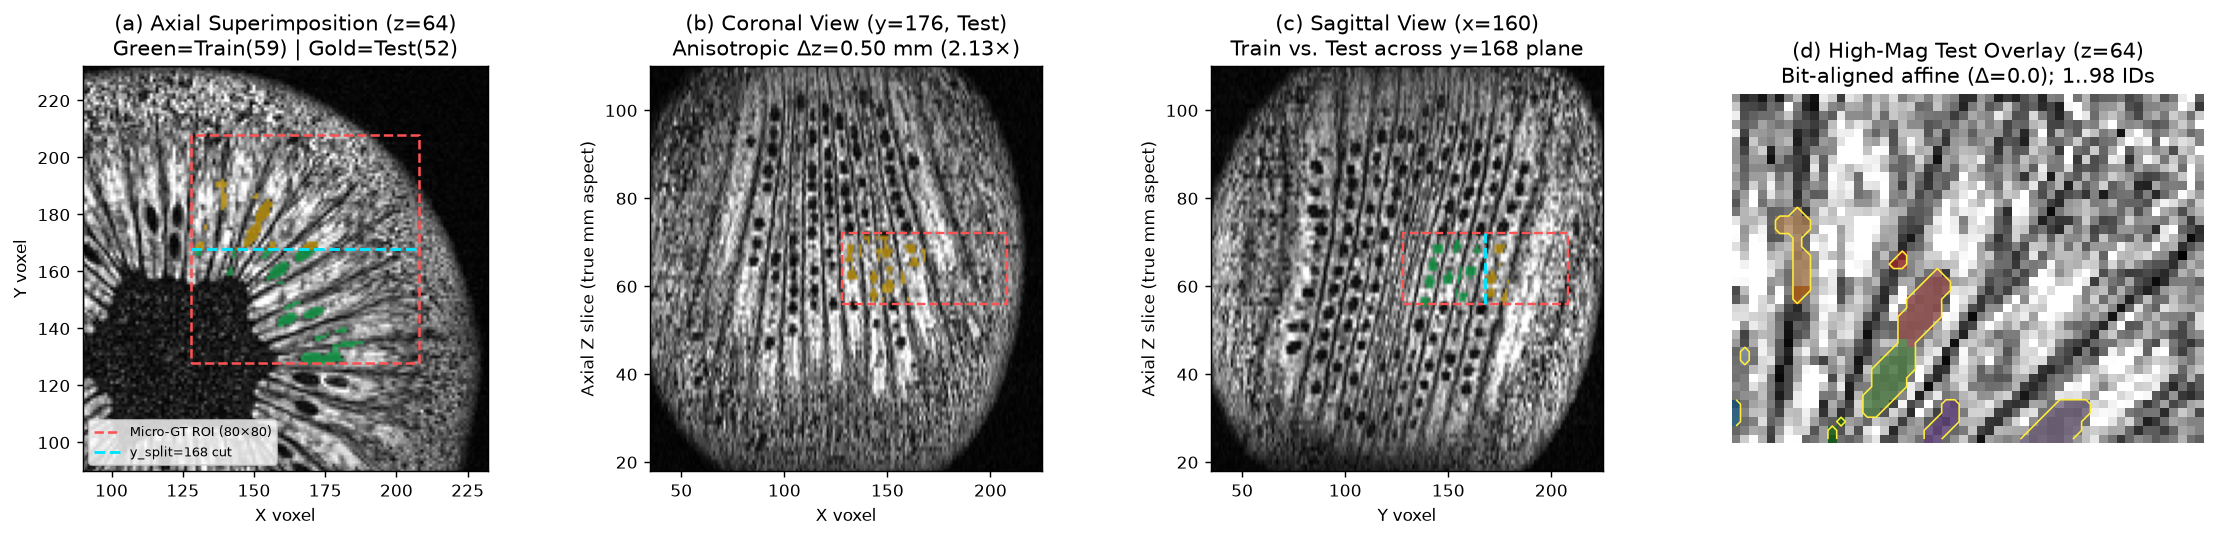

In [4]:
# Figure 1b (Report Figure 2): 4-Panel Tri-Planar 3D Superimposition of Silver Micro-GT on Raw 7T MRI
train_ids = set(int(v) for v in np.unique(ds.train_gt) if v > 0)
test_ids = set(int(v) for v in np.unique(ds.test_gt) if v > 0)
straddle_ids = sorted(train_ids & test_ids)

gt_train_full = np.zeros_like(ds.gt_full, dtype=bool)
gt_test_full = np.zeros_like(ds.gt_full, dtype=bool)
y_cut = ds.ry0 + ds.split_y  # 128 + 40 = 168
gt_train_full[ds.rx0:ds.rx1, ds.ry0:y_cut, ds.rz0:ds.rz1] = ds.train_gt > 0
gt_test_full[ds.rx0:ds.rx1, y_cut:ds.ry1, ds.rz0:ds.rz1] = ds.test_gt > 0

print(f"Affine alignment check (max |MRI - GT affine|): {ds.gt_affine_max_diff:.6f} (BIT-IDENTICAL)")
print(f"ROI bounds: x=[{ds.rx0},{ds.rx1}), y=[{ds.ry0},{ds.ry1}), z=[{ds.rz0},{ds.rz1}) | y_cut={y_cut}")
print(f"Train seeds={len(train_ids)}, Test seeds={len(test_ids)}, Cut-plane straddling seeds={len(straddle_ids)}")

# Append provenance metrics to nb01_prior_audit.json
audit_path = RES_DIR / "nb01_prior_audit.json"
audit_j = json.loads(audit_path.read_text(encoding="utf-8"))
audit_j.update({
    "gt_standard": "semi-automated silver-standard (scripts/curate_micro_gt.py + visual audit)",
    "gt_affine_max_diff": round(float(ds.gt_affine_max_diff), 8),
    "roi_vox_pct_of_volume": round(100.0 * (80 * 80 * 16) / float(np.prod(ds.vol.shape)), 2),
    "n_cut_plane_straddling_seeds": len(straddle_ids),
})
audit_path.write_text(json.dumps(audit_j, indent=2), encoding="utf-8")

def blend_overlay(gray_2d: np.ndarray, m_tr: np.ndarray, m_te: np.ndarray) -> np.ndarray:
    g = np.clip(gray_2d / max(float(np.percentile(gray_2d, 99.5)), 1e-6), 0.0, 1.0)
    rgb = np.stack([g, g, g], axis=-1)
    rgb[m_tr] = 0.42 * rgb[m_tr] + 0.58 * np.array([0.12, 0.88, 0.42])   # Emerald green = Train Wedge
    rgb[m_te] = 0.38 * rgb[m_te] + 0.62 * np.array([1.00, 0.78, 0.08])   # Gold/Amber = Held-Out Test Wedge
    return np.clip(rgb, 0.0, 1.0)

fig, axes = plt.subplots(1, 4, figsize=(17.4, 4.1))
asp_xz = ds.spacing[2] / ds.spacing[0]  # 0.50 / 0.2344 = 2.133 (true physical mm aspect!)

# (a) Axial slice z=64 zoomed cleanly to the equatorial sector
z_ax = 64
ax_rgb = blend_overlay(ds.vol_norm[:, :, z_ax].T, gt_train_full[:, :, z_ax].T, gt_test_full[:, :, z_ax].T)
axes[0].imshow(ax_rgb, origin="lower")
axes[0].plot([ds.rx0, ds.rx1, ds.rx1, ds.rx0, ds.rx0], [ds.ry0, ds.ry0, ds.ry1, ds.ry1, ds.ry0],
             color="#ff5252", lw=1.4, ls="--", label="Micro-GT ROI (80×80)")
axes[0].plot([ds.rx0, ds.rx1], [y_cut, y_cut], color="#00e5ff", lw=1.6, ls="--", label=f"y_split={y_cut} cut")
axes[0].set_xlim(90, 232)
axes[0].set_ylim(90, 232)
axes[0].set_xlabel("X voxel")
axes[0].set_ylabel("Y voxel")
axes[0].set_title(f"(a) Axial Superimposition (z={z_ax})\nGreen=Train(59) | Gold=Test(52)")
axes[0].legend(fontsize=7.0, loc="lower left")

# (b) Coronal slice y=176 (inside Held-Out Test Wedge) in true physical mm aspect
y_cor = 176
cor_rgb = blend_overlay(ds.vol_norm[:, y_cor, :].T, gt_train_full[:, y_cor, :].T, gt_test_full[:, y_cor, :].T)
axes[1].imshow(cor_rgb, origin="lower", aspect=asp_xz)
axes[1].plot([ds.rx0, ds.rx1, ds.rx1, ds.rx0, ds.rx0], [ds.rz0, ds.rz0, ds.rz1, ds.rz1, ds.rz0],
             color="#ff5252", lw=1.3, ls="--")
axes[1].set_xlim(35, 225)
axes[1].set_ylim(18, 110)
axes[1].set_xlabel("X voxel")
axes[1].set_ylabel("Axial Z slice (true mm aspect)")
axes[1].set_title(f"(b) Coronal View (y={y_cor}, Test)\nAnisotropic Δz=0.50 mm (2.13×)")

# (c) Sagittal slice x=160 crossing the y=168 train/test cut plane in true physical mm aspect
x_sag = 160
sag_rgb = blend_overlay(ds.vol_norm[x_sag, :, :].T, gt_train_full[x_sag, :, :].T, gt_test_full[x_sag, :, :].T)
axes[2].imshow(sag_rgb, origin="lower", aspect=asp_xz)
axes[2].plot([ds.ry0, ds.ry1, ds.ry1, ds.ry0, ds.ry0], [ds.rz0, ds.rz0, ds.rz1, ds.rz1, ds.rz0],
             color="#ff5252", lw=1.3, ls="--")
axes[2].plot([y_cut, y_cut], [ds.rz0, ds.rz1], color="#00e5ff", lw=1.6, ls="--")
axes[2].set_xlim(35, 225)
axes[2].set_ylim(18, 110)
axes[2].set_xlabel("Y voxel")
axes[2].set_ylabel("Axial Z slice (true mm aspect)")
axes[2].set_title(f"(c) Sagittal View (x={x_sag})\nTrain vs. Test across y={y_cut} plane")

# (d) High-magnification voxel-level overlay inside Held-Out Test Wedge (z=64)
zx0, zx1, zy0, zy1 = 132, 186, 166, 206
zoom_gray = ds.vol_norm[zx0:zx1, zy0:zy1, z_ax].T
zoom_lbl = ds.gt_full[zx0:zx1, zy0:zy1, z_ax].T
axes[3].imshow(zoom_gray, cmap="gray", origin="lower", vmin=0.0, vmax=1.0)
# Distinct per-instance color overlay (semi-transparent) + crisp contours
uniq_z = [int(v) for v in np.unique(zoom_lbl) if v > 0]
cmap_inst = plt.get_cmap("tab20")
rgba_z = np.zeros((*zoom_lbl.shape, 4), dtype=np.float32)
for idx_u, uid in enumerate(uniq_z):
    r_c, g_c, b_c, _ = cmap_inst(idx_u % 20)
    rgba_z[zoom_lbl == uid] = (r_c, g_c, b_c, 0.52)
axes[3].imshow(rgba_z, origin="lower")
axes[3].contour(zoom_lbl > 0, levels=[0.5], colors=["#ffeb3b"], linewidths=0.9)
axes[3].set_title(f"(d) High-Mag Test Overlay (z={z_ax})\nBit-aligned affine (Δ=0.0); 1..98 IDs")
axes[3].axis("off")

plt.tight_layout()
fig.savefig(FIG_DIR / "fig01b_triplanar_gt_superimposition.png", bbox_inches="tight", dpi=150)
plt.show()


## 4. Manual Ground-Truth Refinement: Workflow Impact & `freeview` / `ITK-SNAP` Procedures

### 4.1 What Happens to the Workflow, Predictions, and Evaluations If You Manually Adjust the GT?

Because `kiwi_ns_lib.py` reads whatever positive integer instance IDs exist in the GT mask dynamically (handling arbitrary non-contiguous `uint16` IDs via `np.unique` and `measure.regionprops`), manual GT refinement operates in two distinct scientific regimes:

#### A. Evaluation-Only Adjustment (Frozen Model, Updated Held-Out Test Wedge `y >= 168`)
- **Model predictions do not change**, including whole-organ OOD safety (`0` polar FPs, `-99.92%` OOD voxels) and the learned `Organ-GPS` spatial prior `z_GPS`.
- **Reported metrics shift diagnostically** to reveal reference-standard sensitivity:
  - **Adding missed faint/small seeds** or **deleting false-positive septa** directly shifts `TP`, `FP`, `FN`, `Recall`, and `RQ` (testing whether the model's test `FP`s are actually real seeds missed by the silver standard).
  - **Tightening or expanding 1-voxel seed boundaries** shifts **Semantic Dice** and **Segmentation Quality (`SQ`)** substantially—because a 40–60-voxel 3D seed changes 3D IoU by `~15–25%` from a single-voxel rim shift.
  - **Splitting a fused GT pair** (into two distinct integer IDs) or **merging an over-split seed** directly changes `Merges`/`Splits` and `PQ`.
  - **Ratio-calibrated whole-fruit count** ($\hat{N}_{\text{cal}} = N_{\text{wf}} \cdot N_{\text{GT,ROI}} / N_{\text{pred,ROI}}$) scales proportionally with the revised ROI seed count.

#### B. Full Pipeline Re-Run (Manually Adjusted Train Wedge `y < 168` + Test Wedge `y >= 168`)
Pass your manually edited NIfTI path via `ds = kns.load_kiwi_dataset(gt_nii_override="MyStuff/kiwi-gt/kiwi_gt_manual_v1.nii.gz")` across Notebooks `01`–`05` without touching the shared silver standard in `data/`:
1. **Prior Audit (`NB 01`) breaks silver-standard circularity:** Recomputing radial bounds `r/R`, core vs. 1-voxel PV rim `I/E_local`, single-seed volume IQR, and `d_NN` on human-curated labels immediately verifies whether Priors 1–3 (`[0.22, 0.65]`, `0.82` onset, `d_min = 0.88 mm`, `V_split = 2.55 mm³`) match human judgment or need updating *before* training.
2. **Supervised targets rebuild automatically:** `build_distance_targets()` recomputes both the binary foreground mask and per-instance normalized 3D Euclidean Distance Transform (`y_d`) for every edited, added, or split seed ID in `train_gt`.
3. **Threshold calibration adapts automatically:** `calibrate_threshold_on_train()` automatically re-locks $\tau_{\text{fg}}^*$ to match your annotation style (higher $\tau_{\text{fg}}^*$ for tight dark cores; lower $\tau_{\text{fg}}^*$ if dimmer PV rims are included).
4. **Unsupervised SSL & LTN unlabeled blocks ($\Omega_U$) remain unchanged**, while the trade-off between human supervised labels ($\mathcal{L}_{\text{sup}}$) and biophysical domain rules ($\mathcal{L}_{\text{anat}} + \mathcal{L}_{\text{phys}}$) adapts cleanly.

---

### 4.2 How to Manually Adjust the GT Safely (Golden Rule + Step-by-Step Procedures)

> **Golden Rule for 3D Instance Masks (`uint16`):** `kiwi_micro_gt_labels.nii.gz` stores **per-seed integer IDs** (`0 = background`, `1..98 = individual seeds`) inside `x ∈ [128, 207]`, `y ∈ [128, 207]`, `z ∈ [56, 71]` (`y_split = 168`).
> - To **refine an existing seed**, paint with **its exact existing integer ID** (e.g. `42`) or erase to `0`.
> - To **add a new seed** or **split a fused twin**, paint with a **brand-new unused integer ID** (`99`, `100`, `101`, …) — never reuse a touching neighbor's ID, or the two blobs will merge into one instance.
> - **Always edit a working copy in git-ignored `MyStuff/kiwi-gt/`** so the shared silver standard stays untouched and Notebook `03b` can auto-discover it for inter-rater Dice / Cohen's $\kappa$ / `STAPLE` consensus!

Create a personal working copy from the repository root:
```bash
mkdir -p MyStuff/kiwi-gt
cp Lab4-Comp-Imag/Kiwi-challenge/data/kiwi_micro_gt_labels.nii.gz \
   MyStuff/kiwi-gt/kiwi_gt_manual_v1.nii.gz
```

#### Procedure A: Manual Voxel Editing in FreeSurfer 8.2.0 `freeview` (macOS)
1. **Launch `freeview` on your working copy** using our launcher script (automatically attaches our custom high-contrast `kiwi_seeds_ColorLUT.txt` supporting vivid distinct colors for IDs `1..2000`):
   ```bash
   ./Lab4-Comp-Imag/Kiwi-challenge/scripts/view_kiwi_freeview.sh --gt MyStuff/kiwi-gt/kiwi_gt_manual_v1.nii.gz
   ```
2. **Enter Voxel Edit mode:** Select `Custom_Manual_GT` in the left *Volumes* list → click **Voxel Edit** (pencil icon, or *Tools → Voxel Edit* / `Cmd+E`). Set **Brush Size = `1`** (or `2`) in **2D** brush mode (avoiding accidental spillover across the `0.50 mm` thick $z$-slices).
3. **Edit seed instances:**
   - Hover over any seed to read its integer ID (`1..98`) in the bottom *Cursor* panel.
   - **Expand/shrink an existing seed:** Enter its exact ID in *Brush Value*; **Left-drag** to paint, **Shift + Left-drag** to erase back to `0`.
   - **Delete a false-positive blob:** Select the **Fill** tool and **Shift + Click** the blob across its slices.
   - **Add a new seed or split a fused twin:** Enter an unused ID (`99`, `100`, …) in *Brush Value* and paint across its 2–4 axial slices while checking Coronal/Sagittal compactness.
   - Toggle overlay visibility anytime with **`Alt+V`**; undo/redo with **`Cmd+Z`** / **`Cmd+Shift+Z`**.
4. **Save:** With `Custom_Manual_GT` selected, press **`Cmd+S`** (*File → Save Volume*).

#### Procedure B: Manual Editing in `ITK-SNAP` (Especially Fast for 3D Clump Splitting)
1. **Open images:** *File → Open Main Image* (`data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz`) → *Segmentation → Open Segmentation* (`MyStuff/kiwi-gt/kiwi_gt_manual_v1.nii.gz`) → jump cursor to `(168, 168, 64)` and click **Update** in the 3D pane.
2. **Edit instances:** Press **`3`** (Paintbrush) or **`2`** (Polygon); press **`S`** to toggle visibility. Add unused IDs (`99`, `100`, …) via *Segmentation → Label Editor*. Set *Paint over = `Clear Label`* when refining near neighbors, or `All Labels` when carving out half of a fused pair with a new ID. Use the **3D Scalpel tool (`6`)** in the 3D window to slice a fused twin clump along a single plane and reassign one half to a new ID in one step.
3. **Save:** *Segmentation → Save Segmentation Image* → `MyStuff/kiwi-gt/kiwi_gt_manual_v1.nii.gz`.

#### Benchmarking / Retraining Against Your Edited GT in Notebooks `01`–`05`
```python
ds = kns.load_kiwi_dataset(gt_nii_override="MyStuff/kiwi-gt/kiwi_gt_manual_v1.nii.gz")
```